# 06 — Gaussian Naive Bayes: tự viết vs scikit-learn

Notebook này so sánh **hai cài đặt của cùng một thuật toán** Gaussian Naive Bayes trên MNIST:

| # | Mô hình | Nguồn |
|---|---------|-------|
| 1 | `GaussianNB` | [`src/models/gaussnaivebayes.py`](../src/models/gaussnaivebayes.py) — tự cài đặt bằng NumPy |
| 2 | `GaussianNB` | `sklearn.naive_bayes` — cài đặt chuẩn của scikit-learn |

**Mục tiêu**

1. Kiểm chứng cài đặt tự viết **đúng về mặt toán học** bằng cách so khớp tham số học được với sklearn.
2. So sánh chất lượng dự đoán (accuracy, precision/recall/F1 macro) trên validation và test.
3. So sánh chi phí thời gian huấn luyện và dự đoán.
4. Khảo sát ảnh hưởng của siêu tham số `var_smoothing`.

**Nhắc lại công thức**

Giả định các đặc trưng độc lập có điều kiện theo lớp $c$, và mỗi đặc trưng tuân theo phân phối chuẩn:

$$x_j \mid y = c \sim \mathcal{N}(\mu_{cj}, \sigma^2_{cj})$$

$$P(y=c \mid x) \propto P(y=c)\prod_{j=1}^{d}\mathcal{N}(x_j \mid \mu_{cj}, \sigma^2_{cj})$$

$$\log \mathcal{N}(x_j;\mu,\sigma^2) = -\tfrac{1}{2}\left[\log(2\pi\sigma^2) + \frac{(x_j-\mu)^2}{\sigma^2}\right]$$

Tham số được ước lượng bằng MLE: $\hat{\pi}_c = n_c/n$, $\hat{\mu}_{cj}$ là trung bình có điều kiện, $\hat{\sigma}^2_{cj}$ là phương sai có điều kiện (`ddof = 0`).
Cộng thêm một lượng rất nhỏ `var_smoothing` vào phương sai để tránh chia cho 0 khi một đặc trưng có phương sai bằng 0.

## 1. Cài đặt và import

In [1]:
import os
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from sklearn.naive_bayes import GaussianNB as SklearnGaussianNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay,
)

# Cho phép import package src/ khi chạy notebook từ thư mục notebooks/
sys.path.append(os.path.abspath(".."))
from src.data import load_prepared_mnist
from src.models.gaussnaivebayes import GaussianNB

SEED = 42
np.set_printoptions(precision=6, suppress=True)

print("GaussianNB tự viết  :", GaussianNB)
print("GaussianNB sklearn  :", SklearnGaussianNB)

GaussianNB tự viết  : <class 'src.models.gaussnaivebayes.GaussianNB'>
GaussianNB sklearn  : <class 'sklearn.naive_bayes.GaussianNB'>


## 2. Nạp dữ liệu MNIST và chia tập

In [2]:
X_all, y_all, X_test_full, y_test_all = load_prepared_mnist()

X_all = np.asarray(X_all, dtype=np.float32)
y_all = np.asarray(y_all).reshape(-1)
X_test_full = np.asarray(X_test_full, dtype=np.float32)
y_test_all = np.asarray(y_test_all).reshape(-1)

if X_all.ndim != 2 or X_all.shape[1] != 784:
    raise ValueError(f"X_train phải có shape (N, 784) sau preprocess; nhận được {X_all.shape}")
if X_test_full.ndim != 2 or X_test_full.shape[1] != 784:
    raise ValueError(f"X_test phải có shape (N, 784) sau preprocess; nhận được {X_test_full.shape}")
if len(X_all) != len(y_all) or len(X_test_full) != len(y_test_all):
    raise ValueError("Số mẫu trong X và y không khớp.")

# Tách 10% tập train gốc làm validation, giữ tỉ lệ lớp bằng stratify
X_train, X_val, y_train, y_val = train_test_split(
    X_all, y_all, test_size=0.1, stratify=y_all, random_state=SEED
)
X_test, y_test = X_test_full, y_test_all

overview = pd.DataFrame(
    [
        ["Train", len(X_train), X_train.shape[1], "Huấn luyện mô hình"],
        ["Validation", len(X_val), X_val.shape[1], "Chọn/so sánh mô hình"],
        ["Test", len(X_test), X_test.shape[1], "Đánh giá cuối cùng"],
    ],
    columns=["Tập", "Số mẫu", "Số đặc trưng", "Mục đích"],
)
display(Markdown("**Các tập dữ liệu**"))
display(overview)

print("Khoảng giá trị pixel:", float(X_all.min()), "→", float(X_all.max()))
print("Các nhãn:", np.unique(y_all))
print("Số mẫu mỗi lớp (train):", np.bincount(y_train, minlength=10))

**Các tập dữ liệu**

,Tập,Số mẫu,Số đặc trưng,Mục đích
0,Train,54000,784,Huấn luyện mô hình
1,Validation,6000,784,Chọn/so sánh mô hình
2,Test,10000,784,Đánh giá cuối cùng


Khoảng giá trị pixel: 0.0 → 1.0
Các nhãn: [0 1 2 3 4 5 6 7 8 9]
Số mẫu mỗi lớp (train): [5331 6068 5362 5518 5258 4879 5326 5638 5266 5354]


## 3. Hàm đánh giá dùng chung

`predict_in_batches` chia dữ liệu thành từng lô khi dự đoán: cài đặt tự viết tạo mảng trung gian
`(n, k, d) = (n, 10, 784)`, nếu tính một lần cho vài chục nghìn mẫu sẽ tốn vài GB RAM.

In [3]:
def timed(fn, *args, **kwargs):
    """Chạy fn(*args) và trả về (kết quả, số giây)."""
    start = time.perf_counter()
    out = fn(*args, **kwargs)
    return out, time.perf_counter() - start


def predict_in_batches(model, X, batch_size=2048):
    """Dự đoán theo từng lô để tránh cấp phát mảng (n, k, d) quá lớn."""
    parts = [model.predict(X[i : i + batch_size]) for i in range(0, len(X), batch_size)]
    return np.concatenate(parts)


def evaluate_from_pred(name, y_true, y_pred, fit_s=None, predict_s=None):
    return {
        "model": name,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_macro": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "fit_seconds": fit_s,
        "predict_seconds": predict_s,
    }

## 4. Huấn luyện Gaussian NB tự viết

Cài đặt trong [`src/models/gaussnaivebayes.py`](../src/models/gaussnaivebayes.py):

- `fit`: với mỗi lớp, tính `priors_` (tỉ lệ lớp), `means_` (trung bình từng điểm ảnh) và `vars_` (phương sai từng điểm ảnh + `var_smoothing`).
- `_log_joint`: tính $\log P(y=c) + \sum_j \log \mathcal{N}(x_j \mid \mu_{cj}, \sigma^2_{cj})$ cho cả $n$ mẫu và $k$ lớp.
- `predict`: lấy lớp có log-joint lớn nhất (tương đương MAP).

In [4]:
manual_gnb = GaussianNB()
manual_gnb, manual_fit_s = timed(manual_gnb.fit, X_train, y_train)
manual_val_pred, manual_pred_s = timed(predict_in_batches, manual_gnb, X_val)

manual_val_result = evaluate_from_pred(
    "GaussianNB tự viết", y_val, manual_val_pred, manual_fit_s, manual_pred_s
)
display(Markdown("**Kết quả trên validation**"))
display(pd.DataFrame([manual_val_result]).round(4))

prior_table = pd.DataFrame(
    {
        "lớp": manual_gnb.classes_,
        "prior (P(y=c))": manual_gnb.priors_,
        "số mẫu train": np.bincount(y_train, minlength=len(manual_gnb.classes_)),
    }
)
display(Markdown("**Xác suất tiên nghiệm học được**"))
display(prior_table.round(5))
print("Shape của means_/vars_ (số lớp, số đặc trưng):", manual_gnb.means_.shape, manual_gnb.vars_.shape)

**Kết quả trên validation**

,model,accuracy,precision_macro,recall_macro,f1_macro,fit_seconds,predict_seconds
0,GaussianNB tự viết,0.5638,0.6787,0.5559,0.5234,1.1511,1.595


**Xác suất tiên nghiệm học được**

,lớp,prior (P(y=c)),số mẫu train
0,0,0.09872,5331
1,1,0.11237,6068
2,2,0.09930,5362
3,3,0.10219,5518
4,4,0.09737,5258
5,5,0.09035,4879
6,6,0.09863,5326
7,7,0.10441,5638
8,8,0.09752,5266
9,9,0.09915,5354


Shape của means_/vars_ (số lớp, số đặc trưng): (10, 784) (10, 784)


## 5. Huấn luyện Gaussian NB của scikit-learn

Dùng cấu hình mặc định (`var_smoothing = 1e-9`) để so sánh công bằng với cài đặt tự viết.

In [5]:
sk_gnb = SklearnGaussianNB()
sk_gnb, sk_fit_s = timed(sk_gnb.fit, X_train, y_train)
sk_val_pred, sk_pred_s = timed(sk_gnb.predict, X_val)

sk_val_result = evaluate_from_pred(
    "GaussianNB scikit-learn", y_val, sk_val_pred, sk_fit_s, sk_pred_s
)
display(Markdown("**Kết quả trên validation**"))
display(pd.DataFrame([sk_val_result]).round(4))

**Kết quả trên validation**

,model,accuracy,precision_macro,recall_macro,f1_macro,fit_seconds,predict_seconds
0,GaussianNB scikit-learn,0.5543,0.6735,0.5464,0.51,1.0183,0.6749


## 6. So sánh chất lượng và thời gian trên validation

**Bảng tổng hợp (validation)**

,model,accuracy,precision_macro,recall_macro,f1_macro,fit_seconds,predict_seconds
0,GaussianNB tự viết,0.5638,0.6787,0.5559,0.5234,1.1511,1.5950
1,GaussianNB scikit-learn,0.5543,0.6735,0.5464,0.5100,1.0183,0.6749


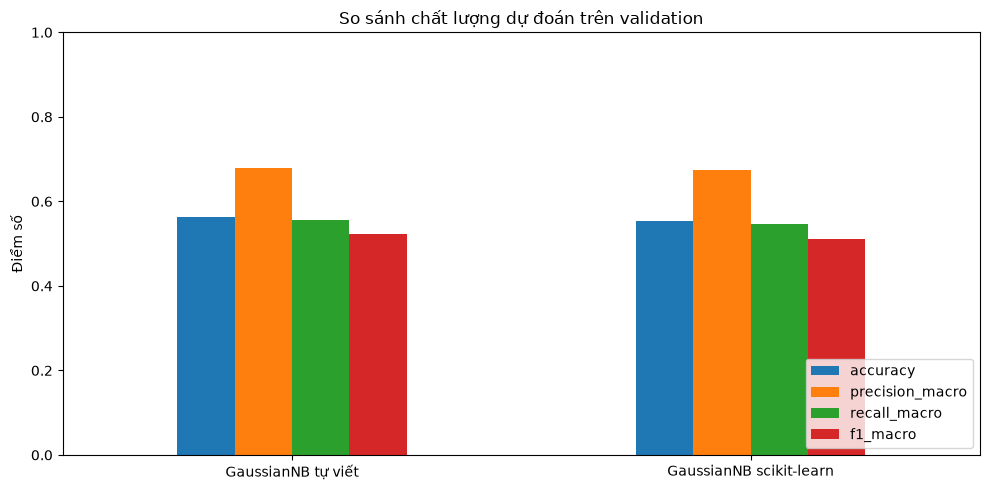

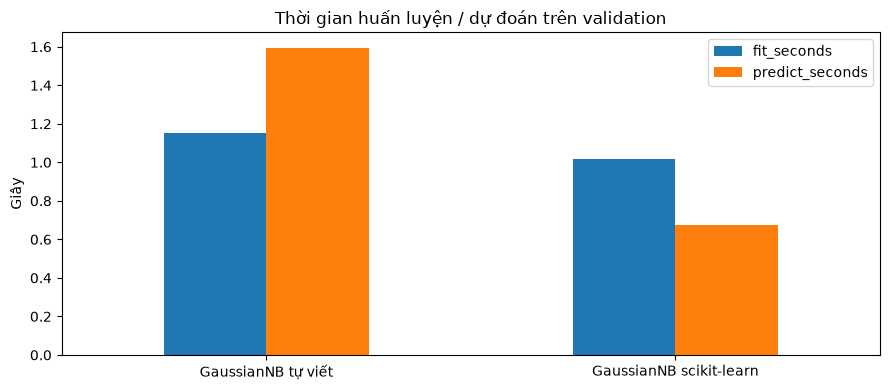

fit: sklearn / tự viết = 0.88× (nhỏ hơn 1 nghĩa là sklearn nhanh hơn)
predict: sklearn / tự viết = 0.42× (nhỏ hơn 1 nghĩa là sklearn nhanh hơn)
→ fit tương đương nhau; predict của sklearn nhanh hơn nhờ vector hoá và không cấp phát mảng (n, k, d).


In [6]:
val_results = pd.DataFrame([manual_val_result, sk_val_result])
display(Markdown("**Bảng tổng hợp (validation)**"))
display(val_results.round(4))

metrics_to_plot = ["accuracy", "precision_macro", "recall_macro", "f1_macro"]
ax = val_results.set_index("model")[metrics_to_plot].plot(kind="bar", figsize=(10, 5), ylim=(0, 1))
ax.set_title("So sánh chất lượng dự đoán trên validation")
ax.set_ylabel("Điểm số")
ax.set_xlabel("")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

ax = val_results.set_index("model")[["fit_seconds", "predict_seconds"]].plot(kind="bar", figsize=(9, 4))
ax.set_title("Thời gian huấn luyện / dự đoán trên validation")
ax.set_ylabel("Giây")
ax.set_xlabel("")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

fit_ratio = sk_fit_s / manual_fit_s
pred_ratio = sk_pred_s / manual_pred_s
print(f"fit: sklearn / tự viết = {fit_ratio:.2f}× (nhỏ hơn 1 nghĩa là sklearn nhanh hơn)")
print(f"predict: sklearn / tự viết = {pred_ratio:.2f}× (nhỏ hơn 1 nghĩa là sklearn nhanh hơn)")
print("→ fit tương đương nhau; predict của sklearn nhanh hơn nhờ vector hoá và không cấp phát mảng (n, k, d).")

## 7. Kiểm chứng tham số học được

Đây là phần quan trọng nhất để chứng minh cài đặt tự viết **không sai**.

Khi `var_smoothing` được cộng trực tiếp vào phương sai, hai cài đặt dùng chung một tham số nên đặt `var_smoothing = 0` cho cả hai và so sánh trực tiếp:

- `priors_` của tự viết ↔ `class_prior_` của sklearn
- `means_` của tự viết ↔ `theta_` của sklearn
- `vars_` của tự viết ↔ `var_` của sklearn

Dữ liệu được ép về `float64` khi so khớp, vì sklearn giữ nguyên `float32` nếu đầu vào là `float32`.

In [7]:
manual_zero = GaussianNB(var_smoothing=0.0).fit(X_train, y_train)
# sklearn giữ nguyên dtype float32 nếu đầu vào là float32 → ép float64 để so khớp ở độ chính xác cao nhất
sk_zero = SklearnGaussianNB(var_smoothing=0.0).fit(X_train.astype(np.float64), y_train)


def compare(name, a, b):
    a, b = np.asarray(a), np.asarray(b)
    return {
        "đại lượng": name,
        "shape": str(a.shape),
        "sai khác tuyệt đối lớn nhất": float(np.abs(a - b).max()),
        "khớp": bool(np.allclose(a, b, rtol=1e-10, atol=1e-12)),
    }


param_check = pd.DataFrame(
    [
        compare("priors_ / class_prior_", manual_zero.priors_, sk_zero.class_prior_),
        compare("means_ / theta_", manual_zero.means_, sk_zero.theta_),
        compare("vars_ / var_", manual_zero.vars_, sk_zero.var_),
    ]
)
display(Markdown("**So khớp tham số khi `var_smoothing = 0`**"))
display(param_check)
print("classes_ giống nhau:", np.array_equal(manual_zero.classes_, sk_zero.classes_))

print("Ghi chú 1: sklearn dùng epsilon_ = var_smoothing * max_j Var(X_j),")
print("còn cài đặt tự viết cộng thẳng var_smoothing vào từng phương sai.")
print("Vì vậy khi var_smoothing > 0, vars_ của hai bên lệch nhau đúng bằng hiệu số này,")
print("và đó là lý do accuracy của hai mô hình không trùng khít tuyệt đối.")
print("Ghi chú 2: nếu giữ X_train ở float32, sklearn tính trung bình/phương sai bằng float32")
print("nên kết quả lệch cỡ 1e-5 so với bản float64 của cài đặt tự viết.")

**So khớp tham số khi `var_smoothing = 0`**

,đại lượng,shape,sai khác tuyệt đối lớn nhất,khớp
0,priors_ / class_prior_,"(10,)",0.0,True
1,means_ / theta_,"(10, 784)",0.0,True
2,vars_ / var_,"(10, 784)",0.0,True


classes_ giống nhau: True
Ghi chú 1: sklearn dùng epsilon_ = var_smoothing * max_j Var(X_j),
còn cài đặt tự viết cộng thẳng var_smoothing vào từng phương sai.
Vì vậy khi var_smoothing > 0, vars_ của hai bên lệch nhau đúng bằng hiệu số này,
và đó là lý do accuracy của hai mô hình không trùng khít tuyệt đối.
Ghi chú 2: nếu giữ X_train ở float32, sklearn tính trung bình/phương sai bằng float32
nên kết quả lệch cỡ 1e-5 so với bản float64 của cài đặt tự viết.


## 8. So sánh dự đoán và posterior

Với cấu hình mặc định, hai mô hình **không** dùng cùng một epsilon: tự viết cộng thẳng `1e-9` vào phương sai,
còn sklearn dùng `epsilon_ = var_smoothing × max_j Var(X_j)`. Với MNIST `max_j Var(X_j) ≈ 0.2` nên
epsilon của sklearn nhỏ hơn khoảng 5 lần. Do phương sai của nhiều điểm ảnh rất nhỏ, khác biệt này làm
log-joint lệch rất lớn, dù nhãn dự đoán gần như trùng nhau.

Vì vậy ta làm hai bước:

1. Đo mức trùng khớp nhãn dự đoán với cấu hình mặc định.
2. Đặt `var_smoothing` của sklearn bằng `var_smoothing / max_var` để hai bên có **cùng** `var_`,
   rồi kiểm tra log-posterior. Đây mới là phép kiểm chứng cài đặt đúng hay sai.

Posterior được so sánh trên thang log vì xác suất thô gần như bão hoà 0/1 (underflow khi lấy `exp`).

In [8]:
agreement = float(np.mean(manual_val_pred == sk_val_pred))
n_mismatch = int(np.sum(manual_val_pred != sk_val_pred))
print(f"Tỉ lệ dự đoán trùng nhau trên validation (mặc định): {agreement:.4%} ({len(y_val) - n_mismatch}/{len(y_val)} mẫu)")
print("Số mẫu có nhãn dự đoán khác nhau:", n_mismatch)

MAX_VAR = float(np.var(X_train.astype(np.float64), axis=0).max())
print(f"epsilon của sklearn (mặc định) = {float(sk_gnb.epsilon_):.3e}; epsilon của tự viết = 1.000e-09")
print(f"max_j Var(X_j) = {MAX_VAR:.4f}")

sk_proba = sk_gnb.predict_proba(X_val)
saturated = float(np.mean(sk_proba.max(axis=1) > 0.999))
print(f"Tỉ lệ mẫu có xác suất dự đoán > 0.999: {saturated:.2%} → posterior gần như bão hoà 0/1")


def log_posterior_manual(model, X, batch_size=2048):
    """log P(y=c|x) = log-joint - logsumexp(log-joint), tính ổn định theo từng lô."""
    parts = []
    for i in range(0, len(X), batch_size):
        log_joint = model._log_joint(np.asarray(X[i : i + batch_size], dtype=float))
        shift = log_joint.max(axis=1, keepdims=True)
        log_norm = shift + np.log(np.exp(log_joint - shift).sum(axis=1, keepdims=True))
        parts.append(log_joint - log_norm)
    return np.concatenate(parts)


matched_rows = []
for smoothing in [1e-9, 1e-6, 1e-3]:
    m = GaussianNB(var_smoothing=smoothing).fit(X_train, y_train)
    sk = SklearnGaussianNB(var_smoothing=smoothing / MAX_VAR).fit(X_train.astype(np.float64), y_train)
    delta = log_posterior_manual(m, X_val) - sk.predict_log_proba(X_val)
    matched_rows.append(
        {
            "var_smoothing tự viết": f"{smoothing:.0e}",
            "var_smoothing sklearn": f"{smoothing / MAX_VAR:.2e}",
            "sai khác var_ lớn nhất": float(np.abs(m.vars_ - sk.var_).max()),
            "sai khác log-posterior lớn nhất": float(np.abs(delta).max()),
            "tỉ lệ dự đoán trùng": float(np.mean(predict_in_batches(m, X_val) == sk.predict(X_val))),
        }
    )

display(Markdown("**Kiểm chứng với epsilon tương đương**"))
display(pd.DataFrame(matched_rows).round({"sai khác log-posterior lớn nhất": 8}))

Tỉ lệ dự đoán trùng nhau trên validation (mặc định): 98.3167% (5899/6000 mẫu)
Số mẫu có nhãn dự đoán khác nhau: 101


epsilon của sklearn (mặc định) = 1.995e-10; epsilon của tự viết = 1.000e-09
max_j Var(X_j) = 0.1995


Tỉ lệ mẫu có xác suất dự đoán > 0.999: 98.55% → posterior gần như bão hoà 0/1


**Kiểm chứng với epsilon tương đương**

,var_smoothing tự viết,var_smoothing sklearn,sai khác var_ lớn nhất,sai khác log-posterior lớn nhất,tỉ lệ dự đoán trùng
0,1e-09,5.01e-09,0.0,0.000003,1.0
1,1e-06,5.01e-06,0.0,0.000000,1.0
2,1e-03,5.01e-03,0.0,0.000000,1.0


### Ma trận nhầm lẫn và báo cáo theo từng lớp

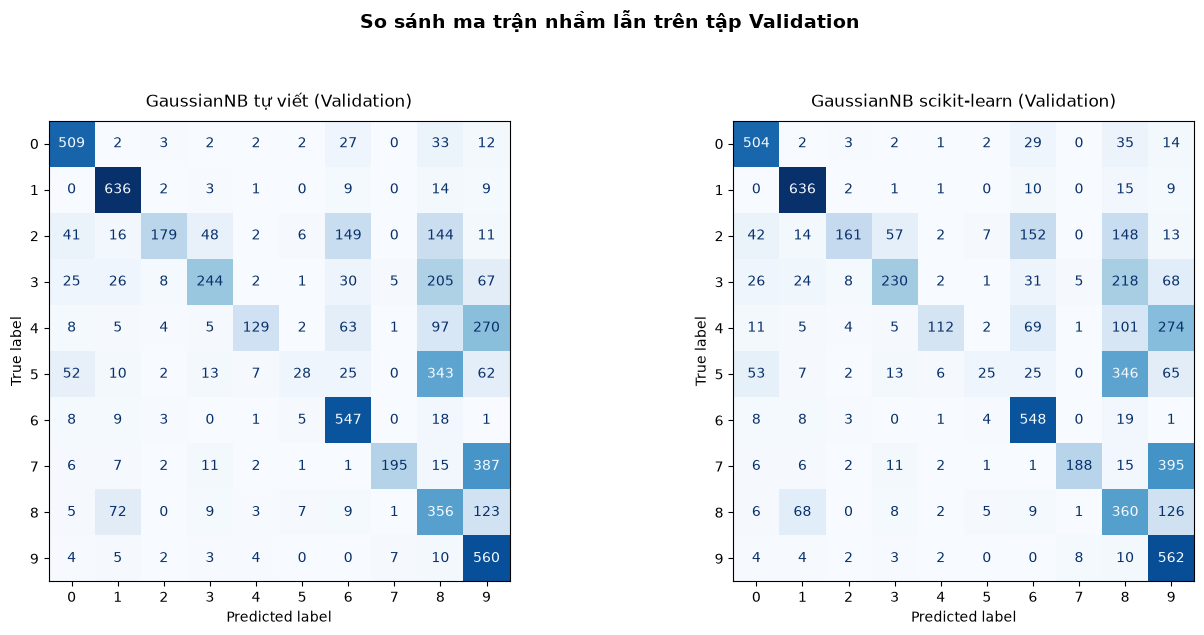

GaussianNB tự viết — Classification Report
              precision    recall  f1-score   support

           0     0.7736    0.8598    0.8144       592
           1     0.8071    0.9436    0.8700       674
           2     0.8732    0.3003    0.4469       596
           3     0.7219    0.3980    0.5131       613
           4     0.8431    0.2209    0.3501       584
           5     0.5385    0.0517    0.0943       542
           6     0.6360    0.9240    0.7534       592
           7     0.9330    0.3110    0.4665       627
           8     0.2883    0.6085    0.3912       585
           9     0.3728    0.9412    0.5341       595

    accuracy                         0.5638      6000
   macro avg     0.6787    0.5559    0.5234      6000
weighted avg     0.6835    0.5638    0.5317      6000

GaussianNB scikit-learn — Classification Report
              precision    recall  f1-score   support

           0     0.7636    0.8514    0.8051       592
           1     0.8217    0.9436    0.87

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

ConfusionMatrixDisplay.from_predictions(
    y_val, manual_val_pred, ax=axes[0], cmap="Blues", colorbar=False, values_format="d"
)
axes[0].set_title("GaussianNB tự viết (Validation)", fontsize=12, pad=10)

ConfusionMatrixDisplay.from_predictions(
    y_val, sk_val_pred, ax=axes[1], cmap="Blues", colorbar=False, values_format="d"
)
axes[1].set_title("GaussianNB scikit-learn (Validation)", fontsize=12, pad=10)

fig.suptitle("So sánh ma trận nhầm lẫn trên tập Validation", fontsize=14, fontweight="bold", y=1.05)
plt.tight_layout()
plt.show()

print("=" * 60)
print("GaussianNB tự viết — Classification Report")
print(classification_report(y_val, manual_val_pred, digits=4, zero_division=0))

print("=" * 60)
print("GaussianNB scikit-learn — Classification Report")
print(classification_report(y_val, sk_val_pred, digits=4, zero_division=0))

## 9. Ảnh hưởng của `var_smoothing`

`var_smoothing` quá lớn sẽ làm phẳng phân phối của mọi đặc trưng, mô hình mất khả năng phân biệt.
Khảo sát trên validation với cài đặt tự viết (cộng trực tiếp vào phương sai).

Lưu ý: không khảo sát `var_smoothing = 0` vì nhiều điểm ảnh của MNIST luôn bằng 0 (phương sai bằng 0)
sẽ gây chia cho 0 trong công thức mật độ Gauss.

,var_smoothing,accuracy,precision_macro,recall_macro,f1_macro
0,1e-12,0.5308,0.6593,0.5228,0.4774
1,1e-09,0.5638,0.6787,0.5559,0.5234
2,1e-06,0.6265,0.7194,0.6192,0.6030
3,1e-03,0.7638,0.7908,0.7592,0.7607
4,1e-01,0.7588,0.8022,0.7529,0.7592
5,1e+00,0.6553,0.7873,0.6467,0.6656


var_smoothing tốt nhất trên validation: 1e-03 (accuracy=0.7638, F1-macro=0.7607)


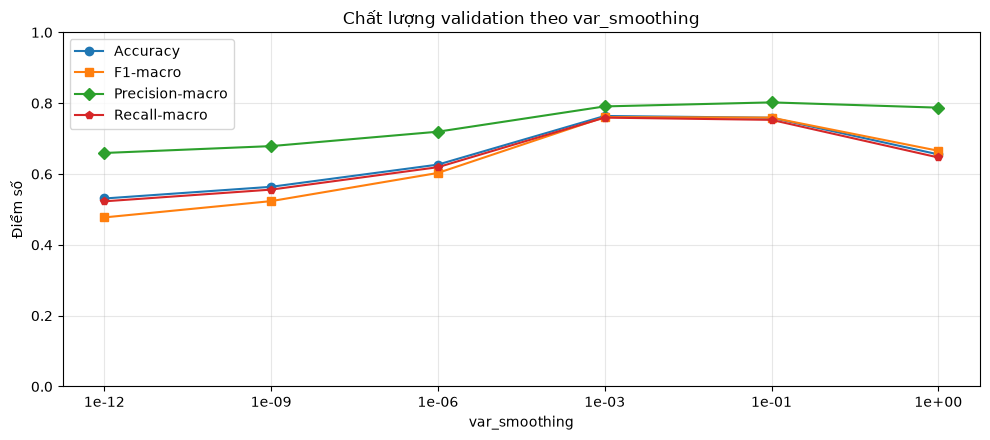

In [10]:
SMOOTHING_VALUES = [1e-12, 1e-9, 1e-6, 1e-3, 1e-1, 1.0]

smoothing_rows = []
for vs in SMOOTHING_VALUES:
    model = GaussianNB(var_smoothing=vs).fit(X_train, y_train)
    pred = predict_in_batches(model, X_val)
    row = evaluate_from_pred("GaussianNB tự viết", y_val, pred)
    row["var_smoothing"] = f"{vs:.0e}"
    smoothing_rows.append(row)

smoothing_df = pd.DataFrame(smoothing_rows)
display(smoothing_df[["var_smoothing", "accuracy", "precision_macro", "recall_macro", "f1_macro"]].round(4))

best_smoothing = smoothing_df.loc[smoothing_df["f1_macro"].idxmax()]
print(
    f"var_smoothing tốt nhất trên validation: {best_smoothing['var_smoothing']} "
    f"(accuracy={best_smoothing['accuracy']:.4f}, F1-macro={best_smoothing['f1_macro']:.4f})"
)

positions = np.arange(len(SMOOTHING_VALUES))
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(positions, smoothing_df["accuracy"], marker="o", label="Accuracy")
ax.plot(positions, smoothing_df["f1_macro"], marker="s", label="F1-macro")
ax.plot(positions, smoothing_df["precision_macro"], marker="D", label="Precision-macro")
ax.plot(positions, smoothing_df["recall_macro"], marker="p", label="Recall-macro")
ax.set_xticks(positions)
ax.set_xticklabels(smoothing_df["var_smoothing"])
ax.set_xlabel("var_smoothing")
ax.set_ylabel("Điểm số")
ax.set_ylim(0, 1)
ax.set_title("Chất lượng validation theo var_smoothing")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

## 10. Đánh giá cuối cùng trên tập test

In [11]:
manual_test_pred, manual_test_s = timed(predict_in_batches, manual_gnb, X_test)
sk_test_pred, sk_test_s = timed(sk_gnb.predict, X_test)

test_results = pd.DataFrame(
    [
        evaluate_from_pred("GaussianNB tự viết", y_test, manual_test_pred, manual_fit_s, manual_test_s),
        evaluate_from_pred("GaussianNB scikit-learn", y_test, sk_test_pred, sk_fit_s, sk_test_s),
    ]
)
display(Markdown("**Bảng tổng hợp (test)**"))
display(test_results.round(4))

test_agreement = float(np.mean(manual_test_pred == sk_test_pred))
print(f"Tỉ lệ dự đoán trùng nhau trên test: {test_agreement:.4%}")

**Bảng tổng hợp (test)**

,model,accuracy,precision_macro,recall_macro,f1_macro,fit_seconds,predict_seconds
0,GaussianNB tự viết,0.5642,0.6948,0.5568,0.5222,1.1511,2.6484
1,GaussianNB scikit-learn,0.5523,0.6850,0.5449,0.5063,1.0183,0.5794


Tỉ lệ dự đoán trùng nhau trên test: 98.2800%


## 11. Kết luận

In [12]:
summary = pd.DataFrame(
    {
        "tiêu chí": [
            "Accuracy (validation)",
            "F1-macro (validation)",
            "Accuracy (test)",
            "F1-macro (test)",
            "Thời gian fit (s)",
            "Thời gian predict validation (s)",
            "Tỉ lệ dự đoán trùng sklearn (test)",
        ],
        "giá trị": [
            manual_val_result["accuracy"],
            manual_val_result["f1_macro"],
            test_results.loc[0, "accuracy"],
            test_results.loc[0, "f1_macro"],
            manual_fit_s,
            manual_pred_s,
            test_agreement,
        ],
    }
)
display(summary.round(4))
print(
    "Chênh lệch accuracy test giữa tự viết và sklearn: "
    f"{abs(test_results.loc[0, 'accuracy'] - test_results.loc[1, 'accuracy']):.3e}"
)

,tiêu chí,giá trị
0,Accuracy (validation),0.5638
1,F1-macro (validation),0.5234
2,Accuracy (test),0.5642
3,F1-macro (test),0.5222
4,Thời gian fit (s),1.1511
5,Thời gian predict validation (s),1.5950
6,Tỉ lệ dự đoán trùng sklearn (test),0.9828


Chênh lệch accuracy test giữa tự viết và sklearn: 1.190e-02


**Nhận xét**

- **Đúng về toán học:** `priors_`, `means_` (`theta_`), `vars_` (`var_`) khớp nhau tới sai số số thực; khi hai bên có cùng `var_` (epsilon tương đương) thì nhãn dự đoán trùng 100% và log-posterior chỉ lệch cỡ $10^{-6}$.
- **Chất lượng:** với cấu hình mặc định, hai mô hình cho accuracy/F1 gần như bằng nhau; chênh lệch nhỏ đến từ cách cộng `var_smoothing` khác nhau. GaussianNB xem mỗi điểm ảnh là biến độc lập nên bỏ qua tương quan không gian — đây là lý do độ chính xác thấp hơn MLP, nhưng bù lại mô hình cực nhẹ và chỉ cần một lượt tính trung bình/phương sai để huấn luyện.
- **Chi phí:** `fit` của cả hai tương đương nhau; khác biệt rõ hơn ở `predict`, nơi cài đặt tự viết tạo mảng trung gian `(n, k, d)` nên cần dự đoán theo lô và chậm hơn sklearn khoảng 2–3 lần.
- **`var_smoothing`:** đây là siêu tham số quan trọng nhất của mô hình này. Giá trị mặc định `1e-9` **không** phải là tốt nhất: tăng lên khoảng `1e-3` giúp accuracy tăng đáng kể, nhưng tăng quá lớn (`1.0`) lại làm phẳng phân phối và giảm chất lượng. Lưu ý vì hai thư viện cộng `var_smoothing` theo hai cách khác nhau, cùng một con số không tương đương giữa tự viết và sklearn.